# Assignment 11A – Reinforcement Learning: Maze Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Define the Maze

In [2]:
# 0 = open, 1 = wall
MAZE = np.array([
    [0, 1, 0, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 1, 0],
    [1, 1, 0, 0, 0],
    [0, 0, 0, 1, 0]
])

START      = (0, 0)
GOAL       = (4, 4)
ROWS, COLS = MAZE.shape
N_STATES   = ROWS * COLS
N_ACTIONS  = 4          # 0=up, 1=down, 2=left, 3=right

def state_id(r, c):
    return r * COLS + c

def step(r, c, action):
    dr, dc = [(-1,0),(1,0),(0,-1),(0,1)][action]
    nr, nc = r + dr, c + dc
    if 0 <= nr < ROWS and 0 <= nc < COLS and MAZE[nr, nc] == 0:
        r, c = nr, nc
    done   = (r, c) == GOAL
    reward = 10 if done else -1
    return r, c, reward, done

## 2. Q-Learning

In [3]:
Q = np.zeros((N_STATES, N_ACTIONS))

ALPHA     = 0.1
GAMMA     = 0.95
EPSILON   = 1.0
EPS_DECAY = 0.995
EPS_MIN   = 0.01
EPISODES  = 2000

rewards_per_episode = []

for _ in range(EPISODES):
    r, c    = START
    total_r = 0

    for _ in range(200):
        s = state_id(r, c)
        if np.random.rand() < EPSILON:
            action = np.random.randint(N_ACTIONS)
        else:
            action = np.argmax(Q[s])

        nr, nc, reward, done = step(r, c, action)
        ns = state_id(nr, nc)

        Q[s, action] += ALPHA * (reward + GAMMA * np.max(Q[ns]) - Q[s, action])

        r, c     = nr, nc
        total_r += reward
        if done:
            break

    EPSILON = max(EPS_MIN, EPSILON * EPS_DECAY)
    rewards_per_episode.append(total_r)

print('Training done.')

Training done.


## 3. Reward Plot

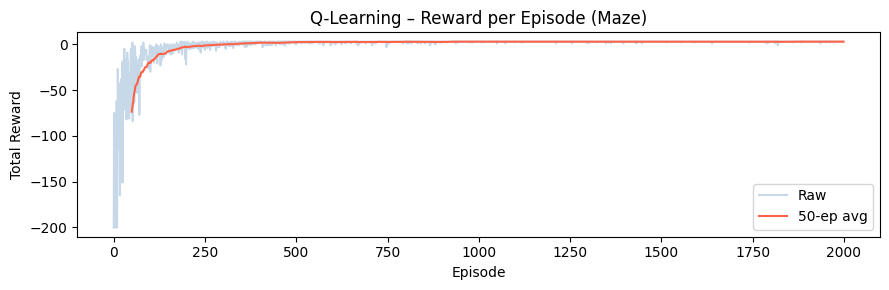

In [4]:
smoothed = np.convolve(rewards_per_episode, np.ones(50)/50, mode='valid')

plt.figure(figsize=(9, 3))
plt.plot(rewards_per_episode, alpha=0.3, color='steelblue', label='Raw')
plt.plot(range(49, EPISODES), smoothed, color='tomato', label='50-ep avg')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Q-Learning – Reward per Episode (Maze)')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Test – Greedy Path

In [5]:
r, c = START
path = [(r, c)]

for _ in range(50):
    action = np.argmax(Q[state_id(r, c)])
    r, c, _, done = step(r, c, action)
    path.append((r, c))
    if done:
        break

print('Path length:', len(path), '| Reached goal:', (r, c) == GOAL)
print('Path:', path)

Path length: 9 | Reached goal: True
Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (3, 3), (3, 4), (4, 4)]
